# Chapter 10: The kernel

Checks [chapter 10](../../book/10-the-kernel.md). The model is **linear in its weights**: its outputs on the
training inputs are `features @ weights`, where the features are fixed Fourier features
`1, cos(k pi x), sin(k pi x)`. This is the model the theorems are about, so there is no amplitude-and-phase
training here. The kernel is `features @ features.T`. The loss is `0.5 * |features @ weights - labels|^2`,
so a gradient step is `weights - learning_rate * features.T @ residual`.

The `residual` is the model's output minus the label. These are measurements. The Lean theorems are the proofs.

Run every cell, top to bottom. A failed check stops the notebook.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "part1"))
sys.path.insert(0, str(Path.cwd() / "experiments" / "part1"))

import numpy as np
import torch
import matplotlib.pyplot as plt
from common import use_style, save_figure, report, NEAREST, VERTICAL, BOUND, MODEL, BEFORE

use_style()
rng = np.random.default_rng(10)


def make_features(inputs, num_terms, frequency_scale=1.0):
    frequencies = np.arange(1, num_terms + 1) * np.pi * frequency_scale
    return np.hstack([np.ones((len(inputs), 1)),
                      np.cos(np.outer(inputs, frequencies)),
                      np.sin(np.outer(inputs, frequencies))])


def get_residual(features, labels, weights):
    return features @ weights - labels


def take_gradient_step(features, labels, learning_rate, weights):
    return weights - learning_rate * features.T @ get_residual(features, labels, weights)


def measure_travel(features, labels, start_weights):
    """Distance from the start to the nearest exact fit (needs features with full row rank)."""
    nearest_fit = start_weights + np.linalg.pinv(features) @ (labels - features @ start_weights)
    assert np.allclose(features @ nearest_fit, labels)
    return float(np.linalg.norm(nearest_fit - start_weights))


NUM_POINTS = 12
inputs = rng.uniform(-1, 1, NUM_POINTS)
labels = rng.normal(size=NUM_POINTS)
features = make_features(inputs, 8)               # 17 weights, 12 points
kernel = features @ features.T
strengths, patterns = np.linalg.eigh(kernel)
print("kernel strengths from", strengths[0], "to", strengths[-1])

kernel strengths from 0.0009079125015205382 to 27.548852505994898


## Claim 1: one step changes the error by learning rate times kernel times error

`residual_gradientStep`: `residual_after = residual_before - learning_rate * K @ residual_before`.
The step is taken on the weights with PyTorch's autograd gradient, and the right side uses only the kernel
and the old error. Five random weight vectors, three learning rates. The check would fail if the step used
the wrong transpose or the weights entered the answer.

In [2]:
max_gap = 0.0
for learning_rate in (0.001, 0.01, 0.05):
    for trial in range(5):
        weights = rng.normal(size=features.shape[1])
        torch_weights = torch.tensor(weights, requires_grad=True)
        torch_features, torch_labels = torch.tensor(features), torch.tensor(labels)
        loss = 0.5 * ((torch_features @ torch_weights - torch_labels) ** 2).sum()
        loss.backward()
        stepped = weights - learning_rate * torch_weights.grad.numpy()

        residual_before = get_residual(features, labels, weights)
        residual_after = get_residual(features, labels, stepped)
        predicted = residual_before - learning_rate * kernel @ residual_before
        max_gap = max(max_gap, float(np.abs(residual_after - predicted).max()))
        assert not np.allclose(residual_after, residual_before)      # the step really moved the error
report("one step: residual_after = residual_before - learning_rate * K residual_before",
       max_gap < 1e-10, f"largest gap {max_gap:.1e}")

[PASS] one step: residual_after = residual_before - learning_rate * K residual_before  (largest gap 1.8e-15)


True

## Claim 2: same kernel, same errors at every step

`residual_iterate_gradientStep_eq`. Model B has a different number of weights and different weights. Its features are
model A's features turned by a random orthogonal matrix and padded with 6 columns of zeros, so
`B B.T = A A.T` exactly. B starts at the turned and padded copy of A's start (the padding is random), so both start with the same error.
Over 200 steps the two error lists must agree. A control: model C uses features of other frequencies, so its kernel
differs; it is started to have the same starting error, and its errors must differ.

[PASS] same kernel, different weights: identical errors for 200 steps  (largest gap 1.8e-15)
[PASS] control: a different kernel gives different errors  (largest gap 7.57e-01)


wrote book/figures/10-same-kernel-same-errors.png


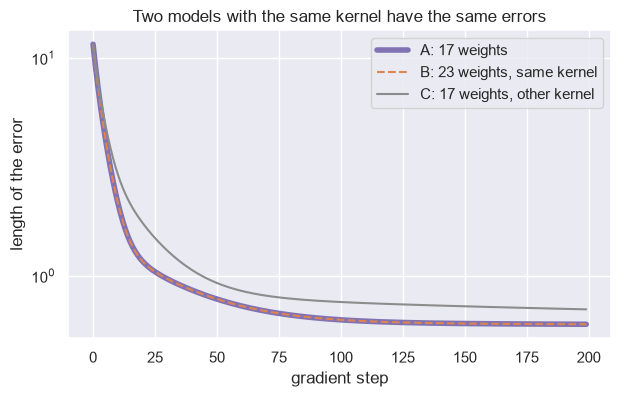

In [3]:
learning_rate = 0.5 / strengths[-1]
start_a = rng.normal(size=features.shape[1])
turn, _ = np.linalg.qr(rng.normal(size=(features.shape[1], features.shape[1])))
features_b = np.hstack([features @ turn, np.zeros((NUM_POINTS, 6))])
start_b = np.concatenate([turn.T @ start_a, rng.normal(size=6)])
assert features_b.shape[1] != features.shape[1] and not np.allclose(start_b[:17], start_a)
assert np.allclose(features_b @ features_b.T, kernel)
features_c = make_features(inputs, 8, frequency_scale=1.3)
start_c = np.linalg.pinv(features_c) @ (labels + get_residual(features, labels, start_a))
assert np.allclose(get_residual(features_c, labels, start_c), get_residual(features, labels, start_a))
assert not np.allclose(features_c @ features_c.T, kernel)

weights_a, weights_b, weights_c = start_a, start_b, start_c
errors_a, errors_b, errors_c = [], [], []
for step in range(200):
    errors_a.append(np.linalg.norm(get_residual(features, labels, weights_a)))
    errors_b.append(np.linalg.norm(get_residual(features_b, labels, weights_b)))
    errors_c.append(np.linalg.norm(get_residual(features_c, labels, weights_c)))
    weights_a = take_gradient_step(features, labels, learning_rate, weights_a)
    weights_b = take_gradient_step(features_b, labels, learning_rate, weights_b)
    weights_c = take_gradient_step(features_c, labels, learning_rate, weights_c)
gap_ab = float(np.abs(np.array(errors_a) - np.array(errors_b)).max())
gap_ac = float(np.abs(np.array(errors_a) - np.array(errors_c)).max())
report("same kernel, different weights: identical errors for 200 steps", gap_ab < 1e-9, f"largest gap {gap_ab:.1e}")
report("control: a different kernel gives different errors", gap_ac > 1e-3, f"largest gap {gap_ac:.2e}")
figure, axis = plt.subplots(figsize=(7, 4))
axis.semilogy(errors_a, color=MODEL, linewidth=4, label="A: 17 weights")
axis.semilogy(errors_b, color=VERTICAL, linewidth=1.5, linestyle="--", label="B: 23 weights, same kernel")
axis.semilogy(errors_c, color=BEFORE, linewidth=1.5, label="C: 17 weights, other kernel")
axis.set_xlabel("gradient step"); axis.set_ylabel("length of the error")
axis.set_title("Two models with the same kernel have the same errors"); axis.legend()
save_figure(figure, "10-same-kernel-same-errors"); plt.show()

## Claim 3: along a pattern of strength `s`, each step multiplies the error by `1 - learning_rate * s`

Take each pattern (eigenvector of the kernel), start so the error is exactly `3 * pattern`, and take a step.
Check the factor for every pattern. Then check the threshold on the strongest pattern: with
`learning_rate * strength` at 1.9 the error shrinks, at 2.1 it grows.

[PASS] every pattern: error_after = (1 - learning_rate * strength) * error_before  (largest gap 5.2e-14)
learning_rate * strength = 0.5: error after 39 steps 1.82e-12
learning_rate * strength = 1.9: error after 39 steps 0.0164
learning_rate * strength = 2.1: error after 39 steps 41.1


wrote book/figures/10-factor-per-step.png


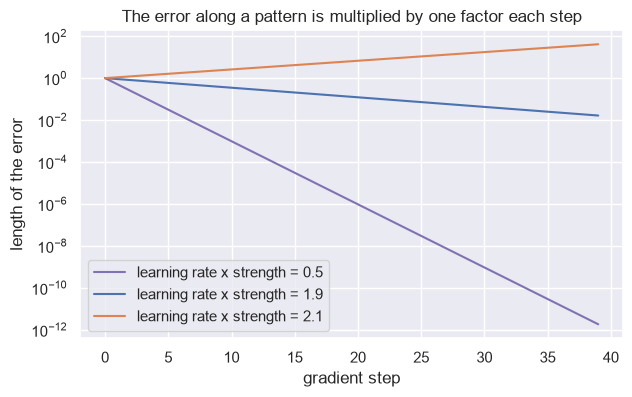

[PASS] learning_rate * strength below 2 shrinks the error, above 2 grows it  (0.016 against 41)


True

In [4]:
worst = 0.0
for index in range(NUM_POINTS):
    strength, pattern = strengths[index], patterns[:, index]
    start = np.linalg.pinv(features) @ (labels + 3.0 * pattern)          # error = 3 * pattern
    assert np.allclose(get_residual(features, labels, start), 3.0 * pattern)
    for learning_rate in (0.3 / strengths[-1], 1.0 / strengths[-1]):
        stepped = take_gradient_step(features, labels, learning_rate, start)
        after = get_residual(features, labels, stepped)
        worst = max(worst, float(np.abs(after - (1 - learning_rate * strength) * 3.0 * pattern).max()))
report("every pattern: error_after = (1 - learning_rate * strength) * error_before", worst < 1e-9, f"largest gap {worst:.1e}")

strongest, pattern = strengths[-1], patterns[:, -1]
start = np.linalg.pinv(features) @ (labels + pattern)
final_errors = {}
figure, axis = plt.subplots(figsize=(7, 4))
for product, color in ((0.5, MODEL), (1.9, NEAREST), (2.1, VERTICAL)):
    weights, errors = start, []
    for step in range(40):
        errors.append(np.linalg.norm(get_residual(features, labels, weights)))
        weights = take_gradient_step(features, labels, product / strongest, weights)
    final_errors[product] = errors[-1]
    print(f"learning_rate * strength = {product}: error after 39 steps {errors[-1]:.3g}")
    axis.semilogy(errors, color=color, label=f"learning rate x strength = {product}")
axis.set_xlabel("gradient step"); axis.set_ylabel("length of the error")
axis.set_title("The error along a pattern is multiplied by one factor each step"); axis.legend()
save_figure(figure, "10-factor-per-step"); plt.show()
report("learning_rate * strength below 2 shrinks the error, above 2 grows it",
       final_errors[1.9] < 1.0 < final_errors[2.1] and final_errors[2.1] > 10.0,
       f"{final_errors[1.9]:.2g} against {final_errors[2.1]:.2g}")

## Claim 4: travel along a pattern is its size divided by the root of its strength

`travel_eq_of_eigen`. For the error `size * pattern` the nearest fit is `size / sqrt(strength)` away from the start.
Check each pattern of the kernel with sizes 3 and 0.5 (the start is zero). Then a mix of patterns:
the travel squared is the sum of `size^2 / strength`.

In [5]:
worst = 0.0
for index in range(NUM_POINTS):
    for size in (3.0, 0.5):
        pattern_labels = -size * patterns[:, index]                  # error at the zero start = size * pattern
        travel = measure_travel(features, pattern_labels, np.zeros(features.shape[1]))
        worst = max(worst, abs(travel - size / np.sqrt(strengths[index])))
report("travel = size / sqrt(strength) for each of the 12 patterns", worst < 1e-9, f"largest gap {worst:.1e}")
sizes = rng.normal(size=NUM_POINTS)
mixed_labels = -patterns @ sizes
travel = measure_travel(features, mixed_labels, np.zeros(features.shape[1]))
report("a mix: travel squared = sum of size^2 / strength", abs(travel ** 2 - np.sum(sizes ** 2 / strengths)) < 1e-8,
       f"travel {travel:.3f}")

[PASS] travel = size / sqrt(strength) for each of the 12 patterns  (largest gap 2.0e-10)
[PASS] a mix: travel squared = sum of size^2 / strength  (travel 35.116)


True

## Claim 5: double descent

Fourier features `1, cos(k pi x), sin(k pi x)` for `k = 1..terms`, so `2 * terms + 1` weights. The target is
`0.8 sin(1.5 pi x)`, 20 noisy training points (noise 0.2), 2000 held-out test points. Below 20 weights least
squares is used. At or above 20 weights, the fit nearest to the zero start, which is what gradient descent from zero
reaches. The travel is the length of the fitted weights. Each value is the median over 200 seeded data sets.
The test error is measured on the held-out points against the noise-free target.

What this can show: the travel peak is a theorem (the weakest strength gets tiny just past 20 weights).
The test-error peak is **measured** here, never proved.

In [6]:
NUM_TRAIN, NUM_TEST, NOISE, NUM_SETS = 20, 2000, 0.2, 200
TERM_COUNTS = list(range(1, 15)) + [16, 20, 24, 32, 48, 64, 128, 256]


def get_target(points):
    return 0.8 * np.sin(1.5 * np.pi * points)


sweep_rng = np.random.default_rng(1010)
test_points = np.linspace(-1, 1, NUM_TEST)
train_sets = [sweep_rng.uniform(-1, 1, NUM_TRAIN) for _ in range(NUM_SETS)]
noises = [sweep_rng.normal(scale=NOISE, size=NUM_TRAIN) for _ in range(NUM_SETS)]
rows = []
for num_terms in TERM_COUNTS:
    test_errors, travels = [], []
    test_features = make_features(test_points, num_terms)
    for train_inputs, noise in zip(train_sets, noises):
        train_features = make_features(train_inputs, num_terms)
        fit = np.linalg.lstsq(train_features, get_target(train_inputs) + noise, rcond=None)[0]
        test_errors.append(np.mean((test_features @ fit - get_target(test_points)) ** 2))
        travels.append(np.linalg.norm(fit))
    rows.append((num_terms, 2 * num_terms + 1, float(np.median(test_errors)), float(np.median(travels))))
for num_terms, num_weights, test_error, travel in rows:
    print(f"terms {num_terms:4d}  weights {num_weights:4d}  test error {test_error:10.3g}  travel {travel:9.3g}")

terms    1  weights    3  test error      0.271  travel     0.461
terms    2  weights    5  test error     0.0967  travel      0.76
terms    3  weights    7  test error     0.0796  travel     0.805
terms    4  weights    9  test error     0.0919  travel     0.859
terms    5  weights   11  test error      0.152  travel     0.957
terms    6  weights   13  test error      0.424  travel      1.17
terms    7  weights   15  test error       2.35  travel       2.3
terms    8  weights   17  test error       52.6  travel      9.98
terms    9  weights   19  test error   1.49e+04  travel       167
terms   10  weights   21  test error   8.08e+04  travel       385
terms   11  weights   23  test error   1.92e+03  travel      60.3
terms   12  weights   25  test error        181  travel        19
terms   13  weights   27  test error       49.9  travel      9.95
terms   14  weights   29  test error       24.6  travel      6.87
terms   16  weights   33  test error       5.88  travel      3.38
terms   20

test error peaks at 21 weights; travel peaks at 21 weights; training points: 20
[PASS] both peaks sit within 4 weights of the number of training points
[PASS] the test-error peak is at least 100 times its value at the smallest and at the largest model  (peak 8.08e+04, smallest 0.271, largest 0.31)
[PASS] the travel peak is at least 100 times the travel of the largest model  (peak 385.1, largest 0.168)


wrote book/figures/10-double-descent.png


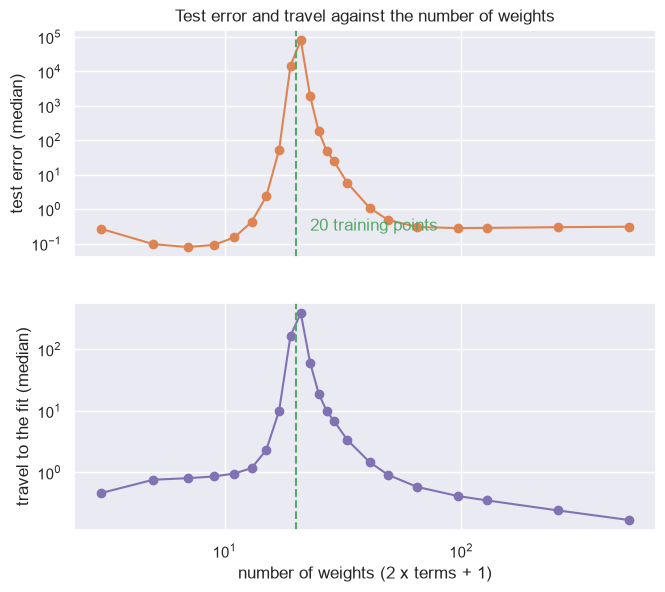

In [7]:
weights_list = np.array([row[1] for row in rows])
test_list = np.array([row[2] for row in rows])
travel_list = np.array([row[3] for row in rows])
peak_test_weights = int(weights_list[test_list.argmax()])
peak_travel_weights = int(weights_list[travel_list.argmax()])
print("test error peaks at", peak_test_weights, "weights; travel peaks at", peak_travel_weights,
      "weights; training points:", NUM_TRAIN)
report("both peaks sit within 4 weights of the number of training points",
       abs(peak_test_weights - NUM_TRAIN) <= 4 and abs(peak_travel_weights - NUM_TRAIN) <= 4)
report("the test-error peak is at least 100 times its value at the smallest and at the largest model",
       test_list.max() > 100 * max(test_list[0], test_list[-1]),
       f"peak {test_list.max():.3g}, smallest {test_list[0]:.3g}, largest {test_list[-1]:.3g}")
report("the travel peak is at least 100 times the travel of the largest model",
       travel_list.max() > 100 * travel_list[-1], f"peak {travel_list.max():.1f}, largest {travel_list[-1]:.3f}")
figure, axes = plt.subplots(2, 1, figsize=(7.5, 6.5), sharex=True)
axes[0].loglog(weights_list, test_list, "o-", color=VERTICAL)
axes[0].set_ylabel("test error (median)")
axes[0].set_title("Test error and travel against the number of weights")
axes[1].loglog(weights_list, travel_list, "o-", color=MODEL)
axes[1].set_ylabel("travel to the fit (median)")
axes[1].set_xlabel("number of weights (2 x terms + 1)")
for axis in axes:
    axis.axvline(NUM_TRAIN, color=BOUND, linestyle="--")
axes[0].text(NUM_TRAIN * 1.15, test_list.min() * 3, "20 training points", color=BOUND)
save_figure(figure, "10-double-descent"); plt.show()

The chapter's table (from `scripts/double_descent.py`, other data sets) lists 5, 21, 65 and 513 weights.
The same rows from this run, to compare:

In [8]:
for num_weights in (5, 21, 65, 513):
    row = rows[list(weights_list).index(num_weights)]
    print(f"weights {num_weights:4d}  test error {row[2]:10.3g}  travel {row[3]:8.3g}")

weights    5  test error     0.0967  travel     0.76
weights   21  test error   8.08e+04  travel      385
weights   65  test error      0.305  travel    0.582
weights  513  test error       0.31  travel    0.168
